In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
crypto_list = ["ADA", "BCH", "BNB", "BTC", "ETC", "ETH", "LINK", "LTC", "XLM", "XRP"]
df_list = {}
for crypto in crypto_list:
    df_list[crypto] = pd.read_csv(f"../data/{crypto}-USDT.csv")
    df_list[crypto]["date"] = pd.to_datetime(df_list[crypto]["date"], unit="ms")
    df_list[crypto] = df_list[crypto].set_index("date")

    duplicated_data = df_list[crypto].index.duplicated(keep='last')
    duplicated_data
    df_list[crypto].loc[duplicated_data]
    df_list[crypto] = df_list[crypto] [~duplicated_data]


In [4]:
df_list['ADA']

,open,high,low,close,volume
date,,,,,
2018-04-17 04:00:00,0.25551,0.28800,0.25551,0.26664,8143693.23
2018-04-17 05:00:00,0.26660,0.27798,0.26010,0.26200,8317923.61
2018-04-17 06:00:00,0.26221,0.26396,0.24800,0.25664,8420095.41
2018-04-17 07:00:00,0.25662,0.26300,0.25489,0.25698,4686043.91
2018-04-17 08:00:00,0.25636,0.25998,0.25229,0.25631,3510038.13
...,...,...,...,...,...
2023-07-03 06:00:00,0.29330,0.29350,0.29080,0.29230,2758504.10
2023-07-03 07:00:00,0.29240,0.29580,0.29220,0.29420,2834458.10
2023-07-03 08:00:00,0.29430,0.29560,0.29340,0.29480,3282098.30


In [5]:
df_list['BTC'].describe()

,open,high,low,close,volume
count,51383.000000,51383.000000,51383.000000,51383.000000,51383.000000
mean,19953.441256,20062.614602,19837.535492,19953.945733,3200.337733
std,16125.883658,16215.651611,16030.902587,16125.807732,4472.817863
min,2870.900000,2950.000000,2817.000000,2919.000000,0.000000
25%,7555.510000,7597.320000,7520.000000,7556.670000,1015.423808
50%,11535.770000,11600.000000,11469.270000,11539.700000,1770.308040
75%,29500.860000,29629.275000,29357.255000,29502.095000,3479.318780
max,68635.120000,69000.000000,68451.190000,68633.690000,137207.188600


In [6]:
len(df_list['ETH'].index.unique()), len(df_list['ETH'])

(51383, 51383)

In [ ]:
https://youtu.be/5GsgrVh5Dqs?list=PLdtqDMvm2lvTASUE94XrjcyCe6seYtFSd&t=1069

In [7]:
df = pd.DataFrame()

for crypto in df_list:
    df[crypto] = df_list[crypto]['close']

df

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
date,,,,,,,,,,
2018-04-17 04:00:00,0.26664,NaN,12.3000,8030.00,NaN,507.60,NaN,129.62,NaN,NaN
2018-04-17 05:00:00,0.26200,NaN,12.2916,7983.00,NaN,505.56,NaN,129.25,NaN,NaN
2018-04-17 06:00:00,0.25664,NaN,12.2720,8025.01,NaN,507.77,NaN,132.90,NaN,NaN
2018-04-17 07:00:00,0.25698,NaN,12.3982,8138.45,NaN,514.28,NaN,134.80,NaN,NaN
2018-04-17 08:00:00,0.25631,NaN,12.4000,8131.60,NaN,516.42,NaN,136.10,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2023-07-03 06:00:00,0.29230,292.5,247.2000,30651.25,20.18,1947.85,6.563,111.88,0.1085,0.4824
2023-07-03 07:00:00,0.29420,295.3,249.5000,30667.19,20.34,1966.83,6.633,112.34,0.1093,0.4807
2023-07-03 08:00:00,0.29480,293.7,248.6000,30640.12,20.15,1960.02,6.618,110.66,0.1073,0.4838


In [8]:
df.dropna(inplace=True)

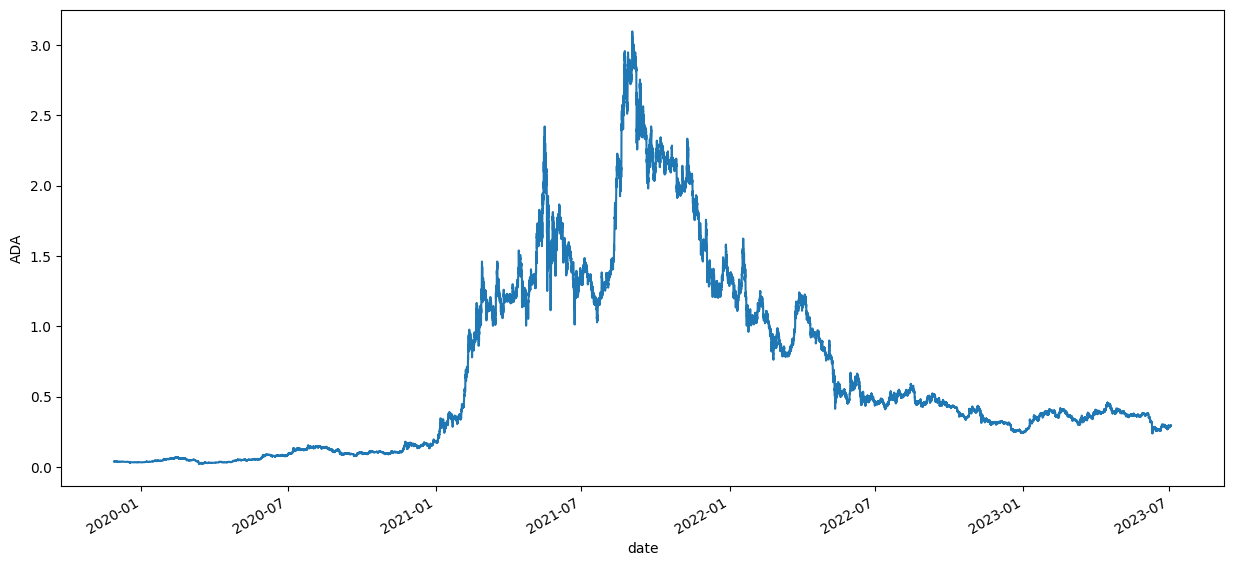

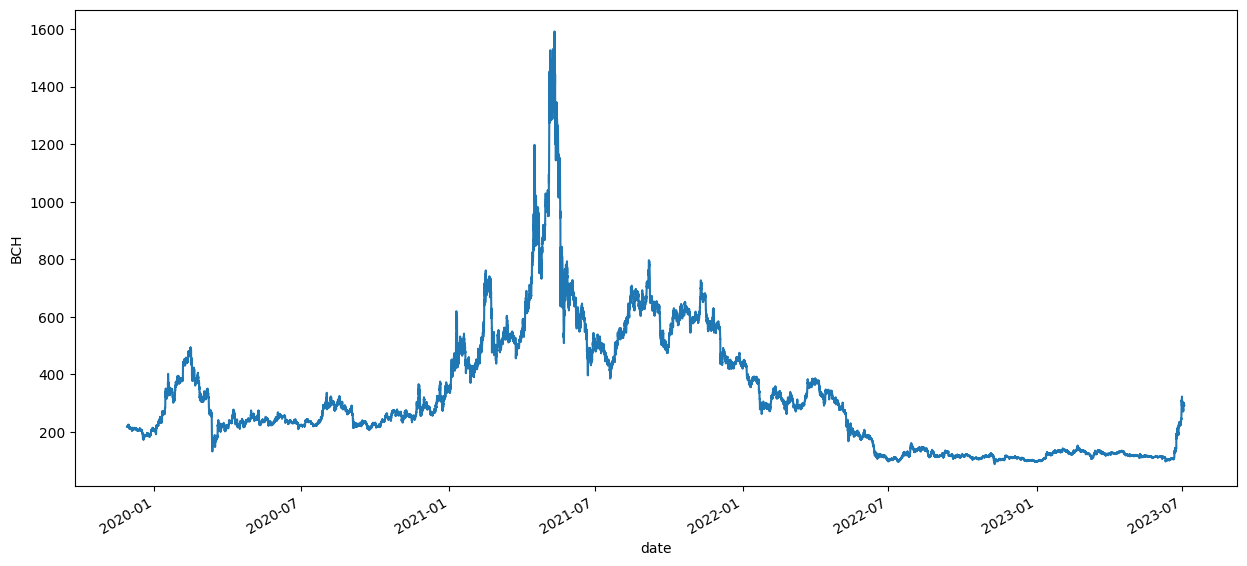

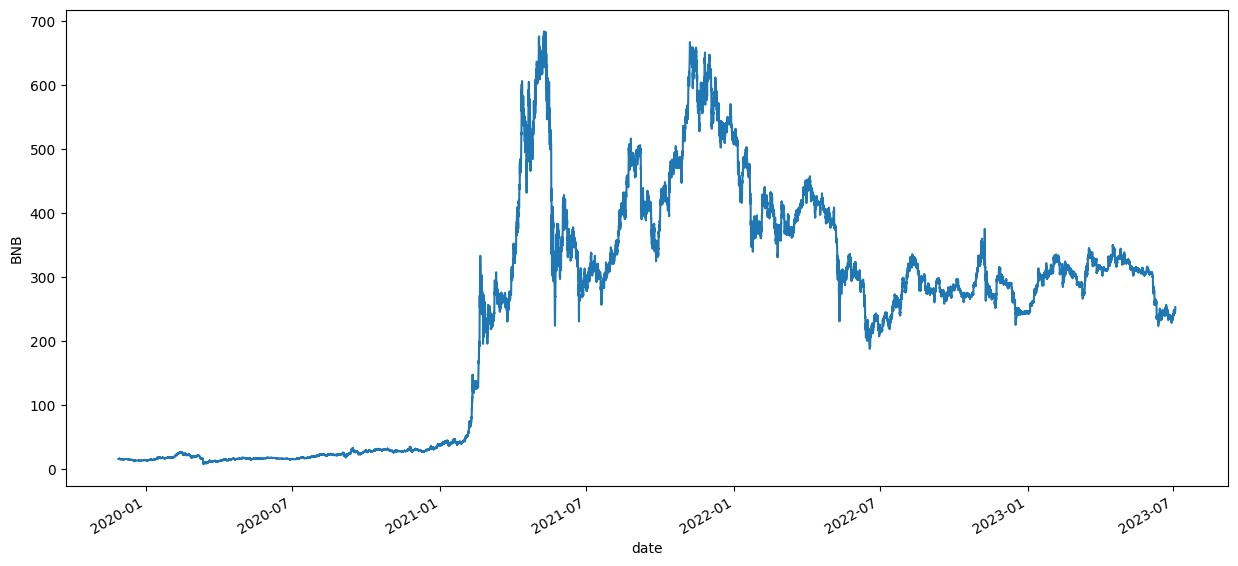

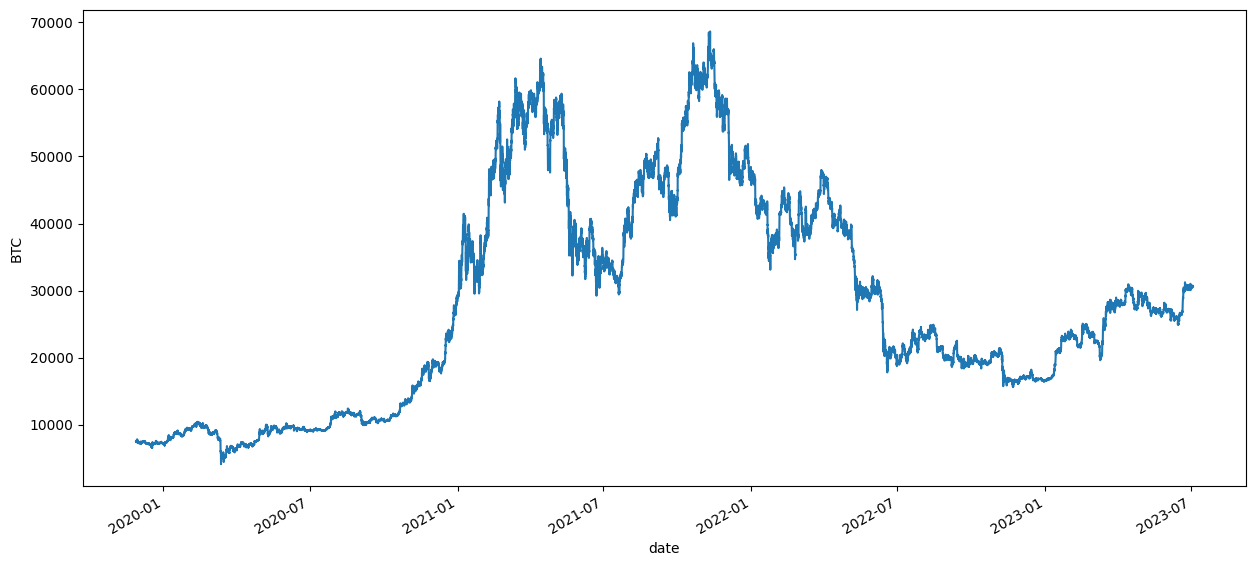

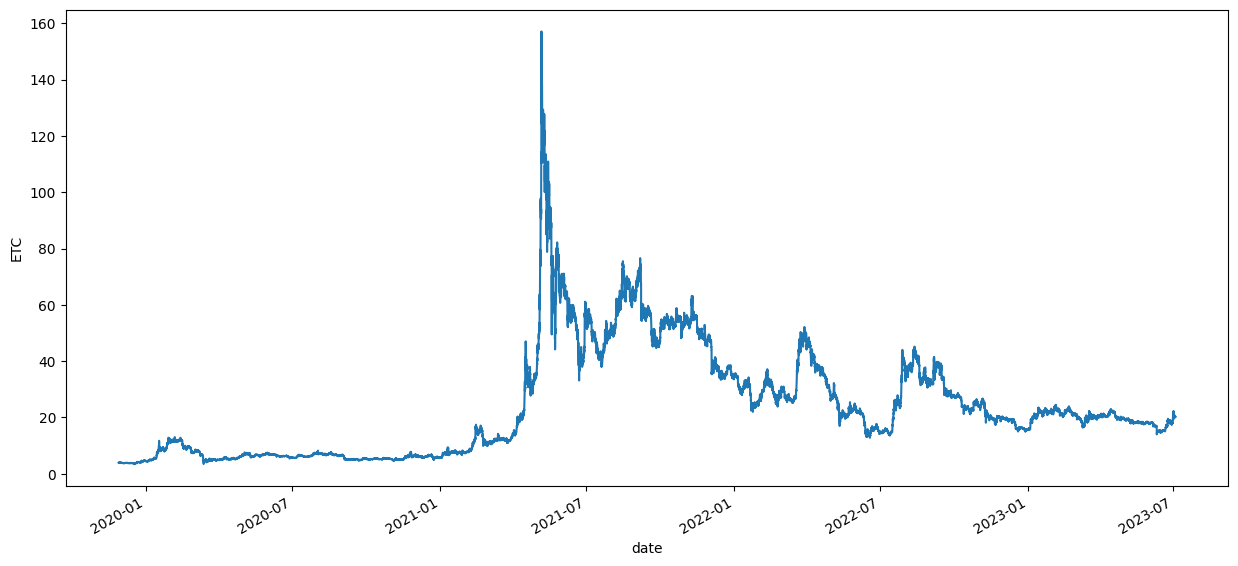

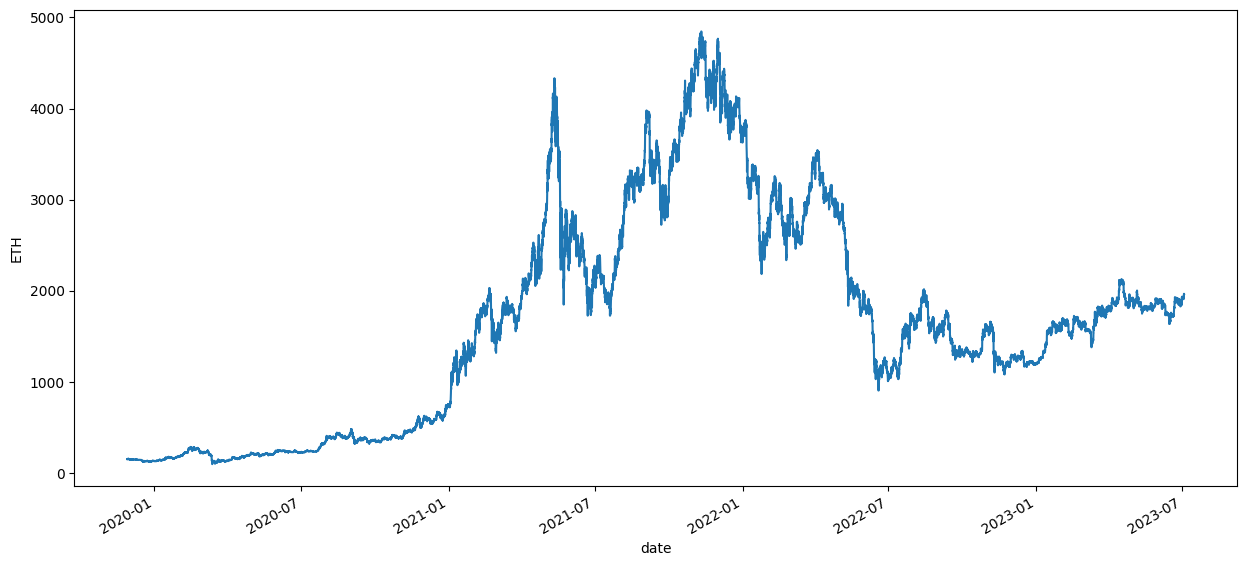

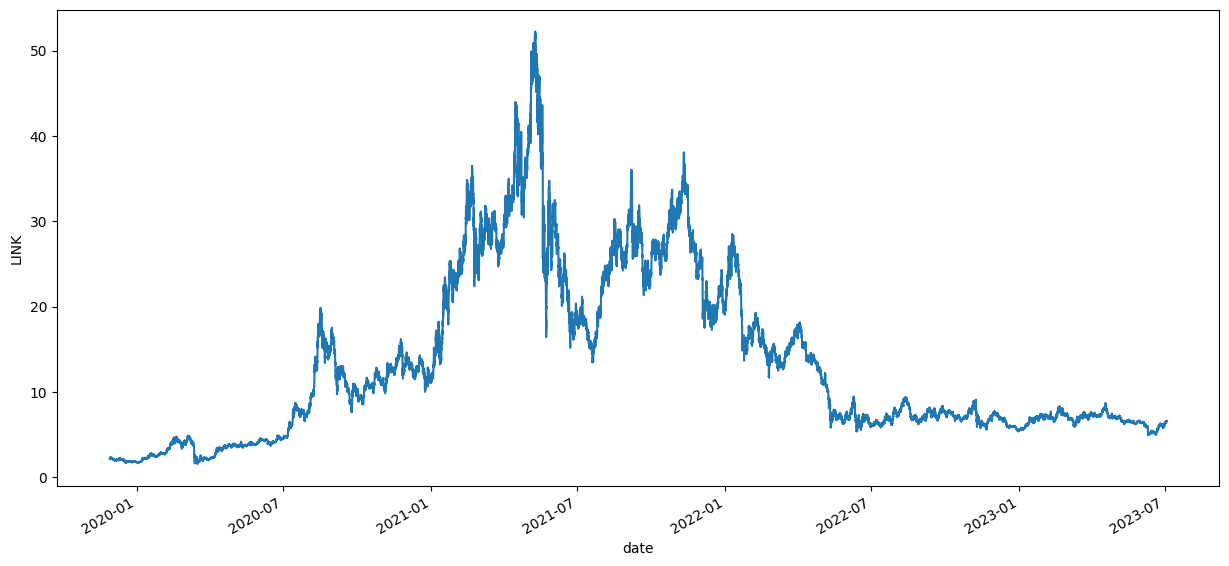

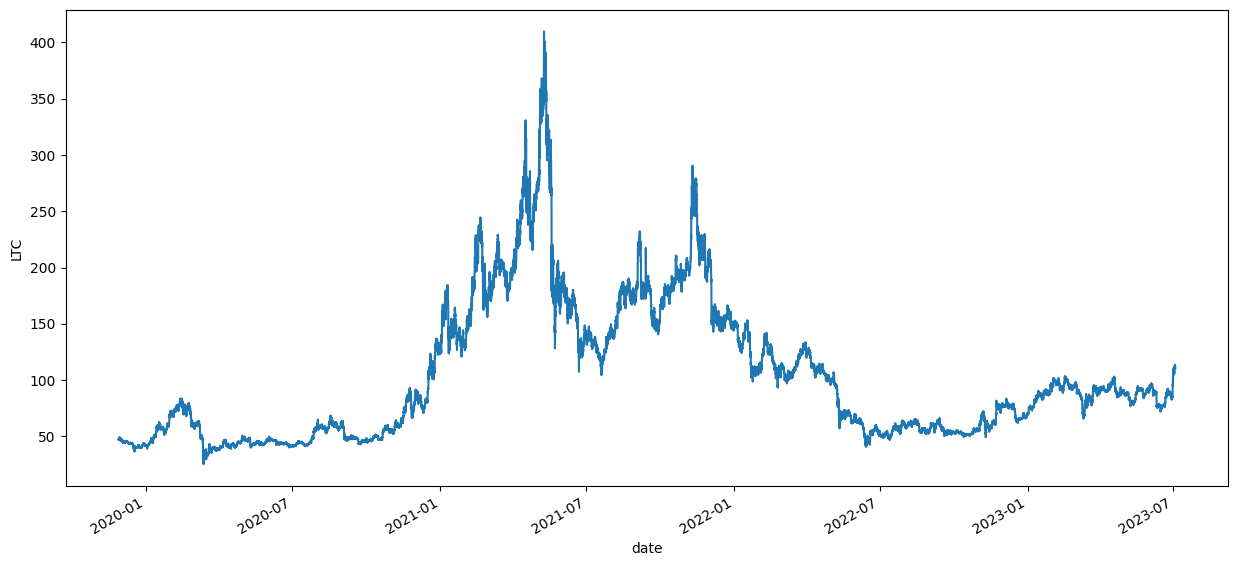

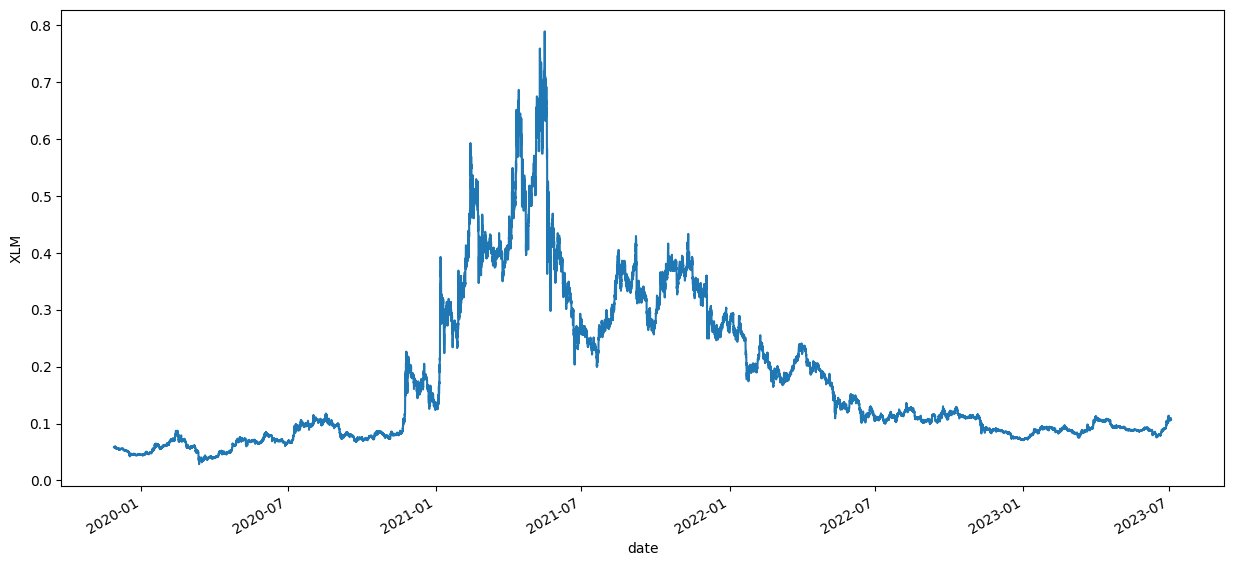

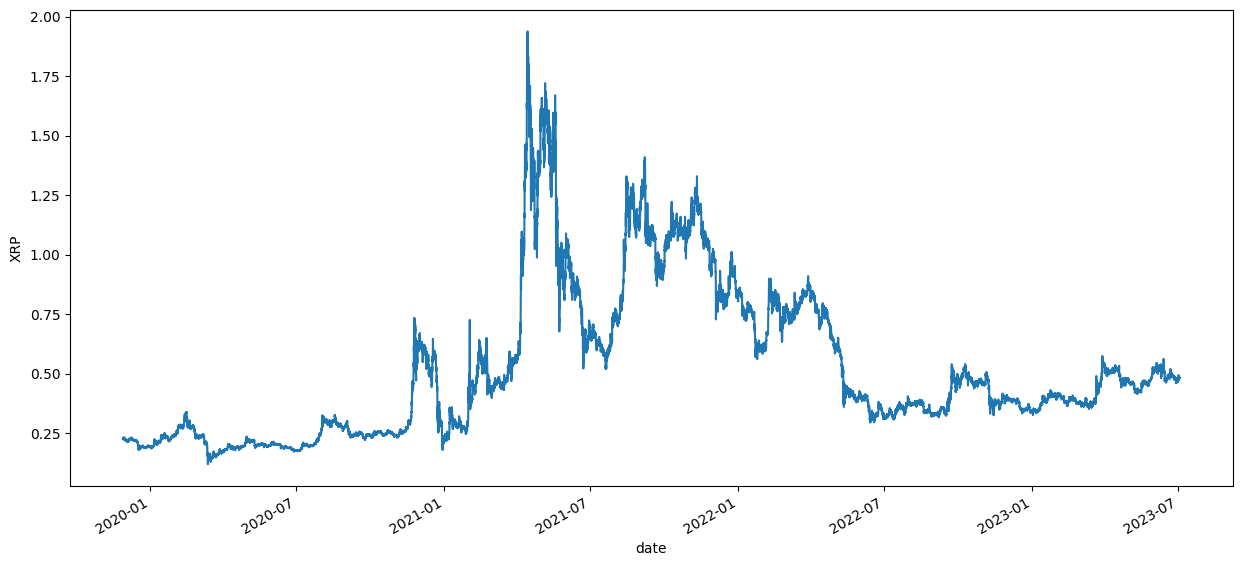

In [9]:
for col in df.columns:
    fig, ax = plt.subplots(figsize=(15,7))
    df[col].plot(label=col)
    ax.set_ylabel(col)
plt.show()


In [10]:
df.corr()

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
ADA,1.000000,0.723569,0.782634,0.859911,0.848417,0.869297,0.819000,0.805404,0.803867,0.887277
BCH,0.723569,1.000000,0.430161,0.690909,0.638144,0.532628,0.890495,0.889421,0.896184,0.767310
BNB,0.782634,0.430161,1.000000,0.822675,0.800248,0.939650,0.610371,0.688569,0.619362,0.834212
BTC,0.859911,0.690909,0.822675,1.000000,0.680973,0.896195,0.860330,0.897080,0.870901,0.853319
ETC,0.848417,0.638144,0.800248,0.680973,1.000000,0.820675,0.659701,0.689580,0.662189,0.833492
ETH,0.869297,0.532628,0.939650,0.896195,0.820675,1.000000,0.700819,0.746219,0.686731,0.861432
LINK,0.819000,0.890495,0.610371,0.860330,0.659701,0.700819,1.000000,0.940221,0.960905,0.836123
LTC,0.805404,0.889421,0.688569,0.897080,0.689580,0.746219,0.940221,1.000000,0.953542,0.861605
XLM,0.803867,0.896184,0.619362,0.870901,0.662189,0.686731,0.960905,0.953542,1.000000,0.833596
XRP,0.887277,0.767310,0.834212,0.853319,0.833492,0.861432,0.836123,0.861605,0.833596,1.000000


<Axes: >

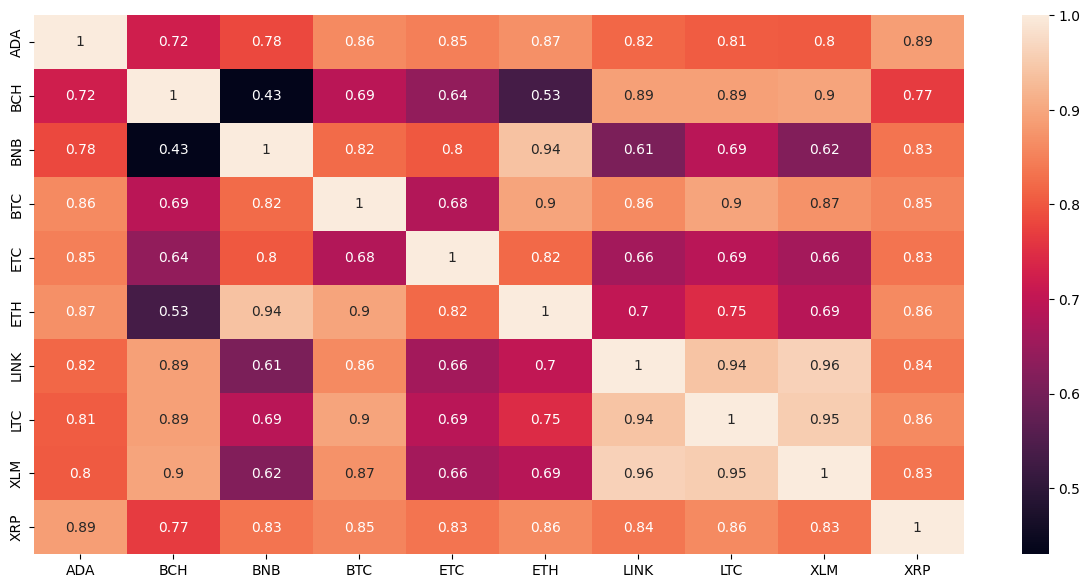

In [11]:
fig, ax = plt.subplots(figsize=(15,7))
sns.heatmap(df.loc[:].corr(), annot=True)

<Axes: >

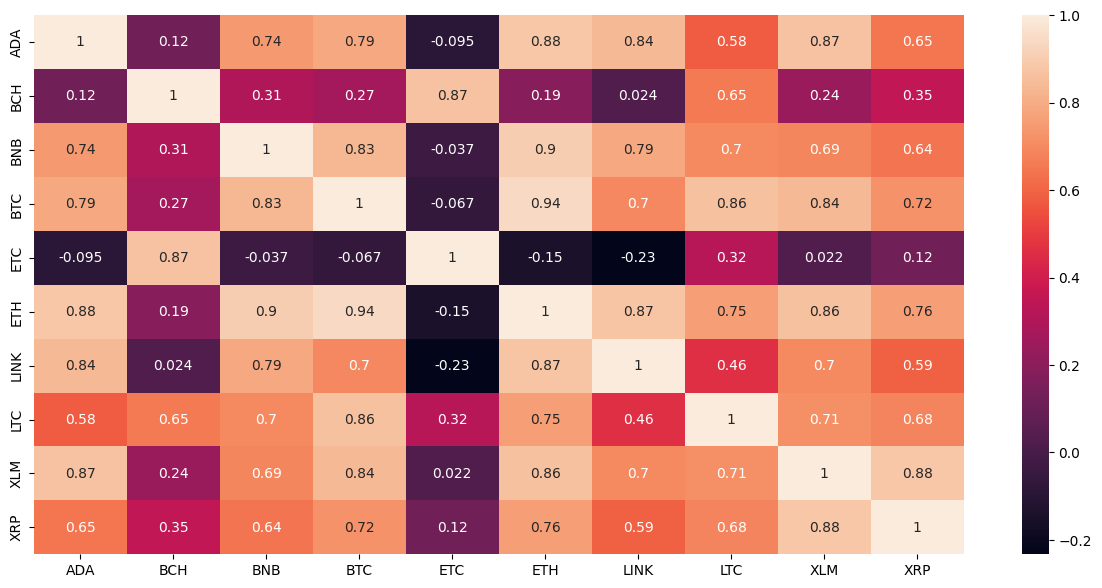

In [12]:
fig, ax = plt.subplots(figsize=(15,7))
sns.heatmap(df.loc['2020'].corr(), annot=True)

In [13]:
df_pct = df.pct_change()
df_pct

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
date,,,,,,,,,,
2019-11-28 10:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-11-28 11:00:00,0.006216,0.000274,0.000523,0.000128,0.003076,0.002911,0.007111,0.002752,0.000172,0.003151
2019-11-28 12:00:00,-0.009009,-0.006894,-0.014893,-0.004736,-0.007933,-0.005146,-0.015321,-0.010980,-0.002578,-0.004602
2019-11-28 13:00:00,-0.001039,0.003494,0.000141,0.001552,0.004675,0.001525,-0.003247,0.001494,-0.002413,-0.000667
2019-11-28 14:00:00,0.007540,0.001741,0.004150,0.000515,0.001551,-0.000861,0.010588,0.002558,0.002418,0.001423
...,...,...,...,...,...,...,...,...,...,...
2023-07-03 06:00:00,-0.003070,-0.015483,0.002027,-0.000729,-0.004440,0.001172,-0.004701,-0.004715,0.001847,0.000207
2023-07-03 07:00:00,0.006500,0.009573,0.009304,0.000520,0.007929,0.009744,0.010666,0.004112,0.007373,-0.003524
2023-07-03 08:00:00,0.002039,-0.005418,-0.003607,-0.000883,-0.009341,-0.003462,-0.002261,-0.014955,-0.018298,0.006449


<Axes: >

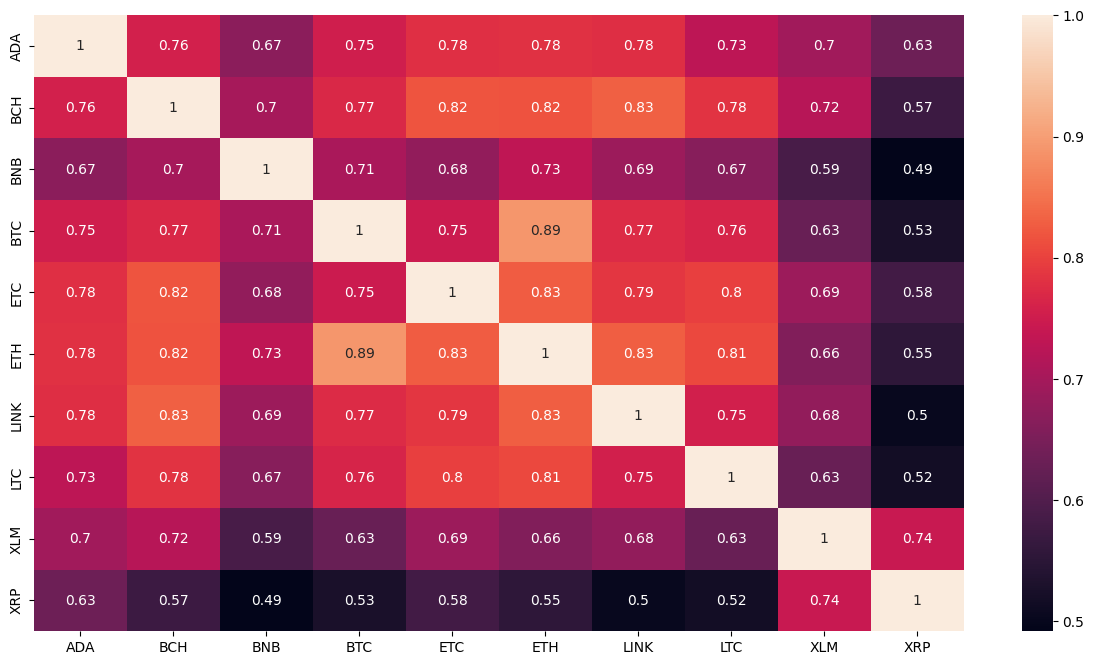

In [14]:
fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(df_pct.loc['2023-3'].corr(), annot=True)

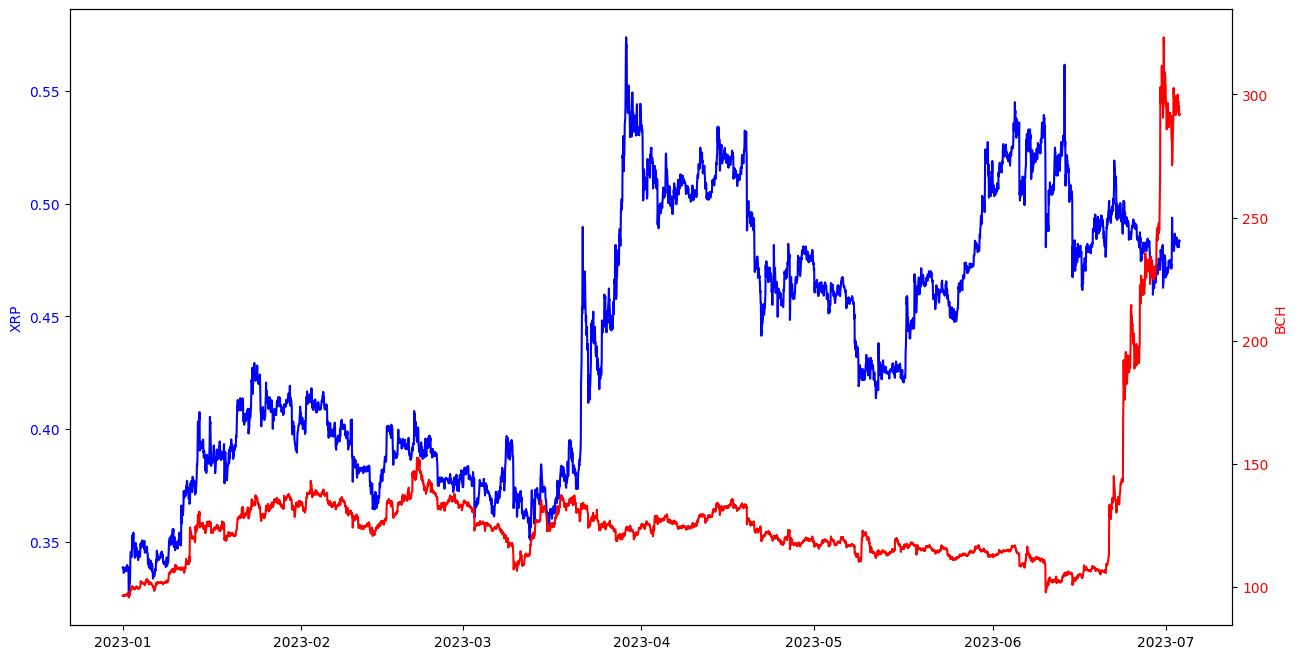

In [15]:
fig, ax = plt.subplots(figsize=(15,8))

data = df.loc['2023']
asset_1 = 'XRP'
asset_2 = 'BCH'

ax.plot(data.index, data[asset_1], color='blue')
ax.set_ylabel(asset_1, color='blue')
ax.tick_params(axis='y', labelcolor='blue')

ax2 = ax.twinx()

ax2.plot(data.index, data[asset_2], color='red')
ax2.set_ylabel(asset_2, color='red')
ax2.tick_params(axis='y', labelcolor='red')



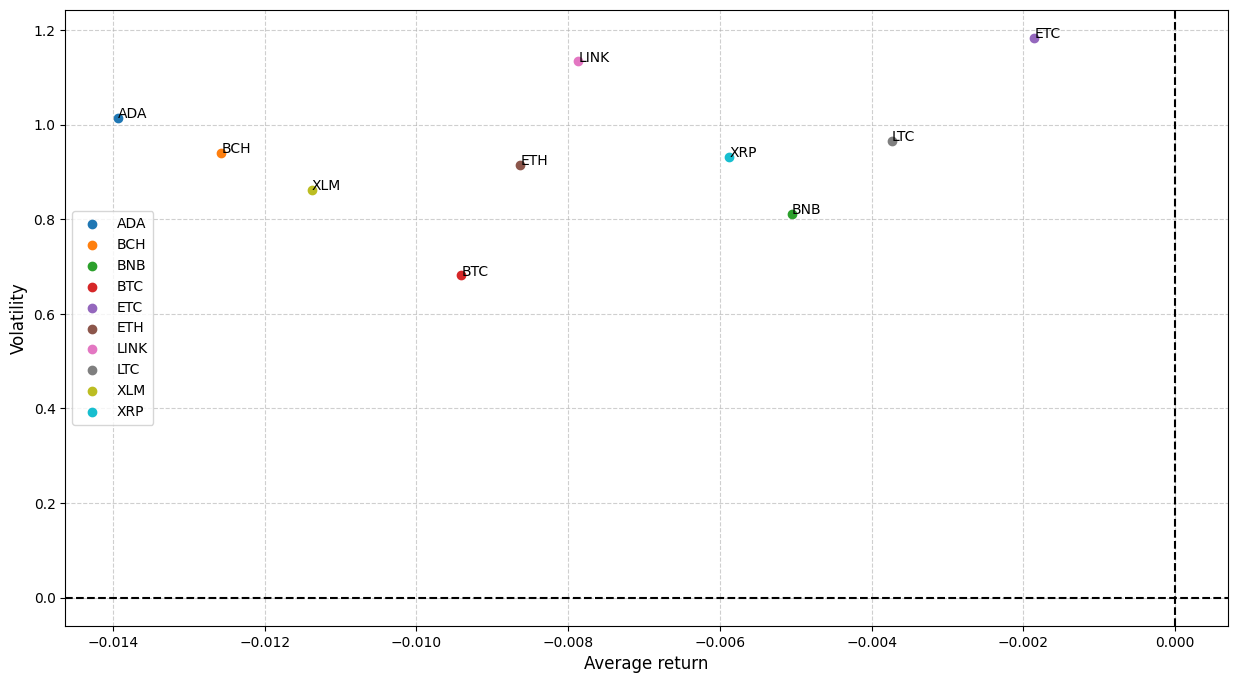

In [18]:
mean_return_list = []
volatility_list = []

temp_data = df_pct.loc['2022']

fig, ax = plt.subplots(figsize=(15,8))

for col in temp_data.columns:

    mean_return = temp_data[col].mean() * 100
    volatility = temp_data[col].std() * 100

    mean_return_list.append(mean_return)
    volatility_list.append(volatility)

    ax.text(mean_return, volatility, col)
    ax.scatter(mean_return, volatility, label=col)

ax.grid(True, linestyle='--', alpha=0.6)
ax.axvline(0, color='black', linestyle='--')
ax.axhline(0, color='black', linestyle='--')

ax.set_xlabel('Average return', fontsize=12)
ax.set_ylabel('Volatility', fontsize=12)

ax.legend()

plt.show()



In [ ]:
https://youtu.be/5GsgrVh5Dqs?list=PLdtqDMvm2lvTASUE94XrjcyCe6seYtFSd&t=2893

In [19]:
temp_data = df_pct.loc[:]
for col in temp_data.columns:
    shapre_ratio = (8760 ** 0.5) * (temp_data[col].mean() / temp_data[col].std())
    print(col, shapre_ratio)

ADA 1.0652078884048417
BCH 0.6007946445423602
BNB 1.2838396574551911
BTC 0.9072830623877229
ETC 0.9818470857671784
ETH 1.2437204766487737
LINK 0.855529740339874
LTC 0.7500566212544104
XLM 0.7096472501733639
XRP 0.7563949295619393


In [22]:
running_max = df['BTC'].cummax()
max_drawdown = (df['BTC'] - running_max) / running_max * 100
max_drawdown

date
2019-11-28 10:00:00     0.000000
2019-11-28 11:00:00     0.000000
2019-11-28 12:00:00    -0.473559
2019-11-28 13:00:00    -0.319137
2019-11-28 14:00:00    -0.267797
                         ...    
2023-07-03 06:00:00   -55.340810
2023-07-03 07:00:00   -55.317585
2023-07-03 08:00:00   -55.357027
2023-07-03 09:00:00   -55.400023
2023-07-03 10:00:00   -55.392388
Name: BTC, Length: 31481, dtype: float64